# Notebook to do the data analysis

## Import Liabraries

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Load dataset

In [30]:
df = sns.load_dataset('tips')
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


### Save the df into .csv

In [31]:
df.to_csv('../data/tips_data.csv', index=False)

#excel
df.to_excel('../data/tips_data.xlsx', index=False)

## Statistics libraries, theme and derived metrics

`scipy` and `statsmodels` are used for hypothesis tests and regression. Plots use a colour-blind-safe palette (Okabe-Ito); every figure is also saved to `../images/` for the report.

Two derived metrics are added: **tip_pct** (tip as a % of the bill, the fairest measure of generosity) and **bill_per_person**.

In [32]:
# Install the statistics libraries (run once; restart the kernel if the import below fails)
%pip install -q scipy statsmodels

Note: you may need to restart the kernel to use updated packages.


In [33]:
import os
import warnings

import scipy.stats as stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multicomp import pairwise_tukeyhsd

warnings.filterwarnings("ignore", category=FutureWarning)

# ---- Colour-blind-safe palette (Okabe-Ito) --------------------------------
BLUE, ORANGE, GREEN, PINK = "#0072B2", "#E69F00", "#009E73", "#CC79A7"
VERMILLION, INK, MUTED = "#D55E00", "#222222", "#6B7280"
CAT = [BLUE, ORANGE, GREEN, PINK]            # fixed order for categorical levels
DIVERGING = sns.diverging_palette(220, 20, as_cmap=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 11, "axes.edgecolor": "#BBBBBB", "grid.color": "#E5E7EB",
    "axes.spines.top": False, "axes.spines.right": False,
})

os.makedirs("../images", exist_ok=True)

def save_fig(name):
    """Save the current figure for the written report (call BEFORE plt.show())."""
    plt.savefig(f"../images/{name}.png", dpi=300, bbox_inches="tight")

In [34]:
# Derived metrics used throughout the report
DAY_ORDER = ["Thur", "Fri", "Sat", "Sun"]
df["day"] = pd.Categorical(df["day"], categories=DAY_ORDER, ordered=True)
df["tip_pct"] = df["tip"] / df["total_bill"] * 100           # tip as % of the bill
df["bill_per_person"] = df["total_bill"] / df["size"]

NUM_COLS = ["total_bill", "tip", "size", "tip_pct"]
CAT_COLS = ["sex", "smoker", "day", "time"]
df.head()

,total_bill,tip,sex,smoker,day,time,size,tip_pct,bill_per_person
0,16.99,1.01,Female,No,Sun,Dinner,2,5.944673,8.495000
1,10.34,1.66,Male,No,Sun,Dinner,3,16.054159,3.446667
2,21.01,3.50,Male,No,Sun,Dinner,3,16.658734,7.003333
3,23.68,3.31,Male,No,Sun,Dinner,2,13.978041,11.840000
4,24.59,3.61,Female,No,Sun,Dinner,4,14.680765,6.147500


## Data composition

In data composition we check:
1. The structure of the dataset (rows and columns)
2. The data types of each column
3. The presence of any missing values
4. Basic statistics (mean, median, mode, standard deviation, etc.) for numerical columns
5. The distribution of categorical variables

In [35]:
df

,total_bill,tip,sex,smoker,day,time,size,tip_pct,bill_per_person
0,16.99,1.01,Female,No,Sun,Dinner,2,5.944673,8.495000
1,10.34,1.66,Male,No,Sun,Dinner,3,16.054159,3.446667
2,21.01,3.50,Male,No,Sun,Dinner,3,16.658734,7.003333
3,23.68,3.31,Male,No,Sun,Dinner,2,13.978041,11.840000
4,24.59,3.61,Female,No,Sun,Dinner,4,14.680765,6.147500
...,...,...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3,20.392697,9.676667
240,27.18,2.00,Female,Yes,Sat,Dinner,2,7.358352,13.590000
241,22.67,2.00,Male,Yes,Sat,Dinner,2,8.822232,11.335000
242,17.82,1.75,Male,No,Sat,Dinner,2,9.820426,8.910000


In [36]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype   
---  ------           --------------  -----   
 0   total_bill       244 non-null    float64 
 1   tip              244 non-null    float64 
 2   sex              244 non-null    category
 3   smoker           244 non-null    category
 4   day              244 non-null    category
 5   time             244 non-null    category
 6   size             244 non-null    int64   
 7   tip_pct          244 non-null    float64 
 8   bill_per_person  244 non-null    float64 
dtypes: category(4), float64(4), int64(1)
memory usage: 11.2 KB


In [37]:
df.describe()

,total_bill,tip,size,tip_pct,bill_per_person
count,244.000000,244.000000,244.000000,244.000000,244.00000
mean,19.785943,2.998279,2.569672,16.080258,7.88823
std,8.902412,1.383638,0.951100,6.107220,2.91435
min,3.070000,1.000000,1.000000,3.563814,2.87500
25%,13.347500,2.000000,2.000000,12.912736,5.80250
50%,17.795000,2.900000,2.000000,15.476977,7.25500
75%,24.127500,3.562500,3.000000,19.147549,9.39000
max,50.810000,10.000000,6.000000,71.034483,20.27500


### 1.1 Data quality and numerical summary

In [38]:
# --- Data quality: types, missing values, duplicates, cardinality ---
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(),
})
display(quality)
print(f"Rows: {df.shape[0]} | Columns: {df.shape[1]}")
print(f"Duplicated rows: {df.duplicated().sum()}")

,dtype,missing,missing_%,unique_values
total_bill,float64,0,0.0,229
tip,float64,0,0.0,123
sex,category,0,0.0,2
smoker,category,0,0.0,2
day,category,0,0.0,4
time,category,0,0.0,2
size,int64,0,0.0,6
tip_pct,float64,0,0.0,241
bill_per_person,float64,0,0.0,235


Rows: 244 | Columns: 9
Duplicated rows: 1


In [39]:
# --- Extended numerical summary ---
num_summary = df[NUM_COLS].agg(["count", "mean", "median", "std", "min", "max", "skew", "kurt"]).T
num_summary["mode"] = [df[c].mode().iloc[0] for c in NUM_COLS]
num_summary["cv_%"] = num_summary["std"] / num_summary["mean"] * 100   # coefficient of variation
display(num_summary.round(2))

,count,mean,median,std,min,max,skew,kurt,mode,cv_%
total_bill,244.0,19.79,17.80,8.90,3.07,50.81,1.13,1.22,13.42,44.99
tip,244.0,3.00,2.90,1.38,1.00,10.00,1.47,3.65,2.00,46.15
size,244.0,2.57,2.00,0.95,1.00,6.00,1.45,1.73,2.00,37.01
tip_pct,244.0,16.08,15.48,6.11,3.56,71.03,3.35,27.13,14.48,37.98


**Interpretation**

- The dataset contains **244 restaurant bills and 7 original variables** (2 continuous: `total_bill`, `tip`; 1 count: `size`; 4 categorical: `sex`, `smoker`, `day`, `time`). There are **no missing values**, so no imputation is needed.
- One row is an exact duplicate (0.4 % of the data). Two different tables can plausibly pay the identical bill and tip, so it was **kept**.
- All three money-related measures are **right-skewed**: the mean exceeds the median for the bill (\$19.79 vs \$17.80), the tip (\$3.00 vs \$2.90) and the tip percentage (16.1 % vs 15.5 %). A few large bills pull the averages upwards, so the **median is the more representative "typical" value**.
- Variation is high: the coefficient of variation is about 45 % for the bill and 46 % for the tip, i.e. bill sizes differ greatly from table to table.
- Tip percentage has a very high skewness (3.35) and kurtosis (27): this is driven by a single extreme tip of **71 %** of the bill, which is probably a data-entry error or an unusual gesture and is examined further in the distribution section.

### 1.2 Categorical composition

In [40]:
# --- Categorical composition ---
for c in CAT_COLS + ["size"]:
    t = df[c].value_counts().to_frame("count")
    t["percent"] = (t["count"] / len(df) * 100).round(1)
    print(f"\n{c.upper()}")
    display(t)


SEX


,count,percent
sex,,
Male,157,64.3
Female,87,35.7



SMOKER


,count,percent
smoker,,
No,151,61.9
Yes,93,38.1



DAY


,count,percent
day,,
Sat,87,35.7
Sun,76,31.1
Thur,62,25.4
Fri,19,7.8



TIME


,count,percent
time,,
Dinner,176,72.1
Lunch,68,27.9



SIZE


,count,percent
size,,
2,156,63.9
3,38,15.6
4,37,15.2
5,5,2.0
1,4,1.6
6,4,1.6


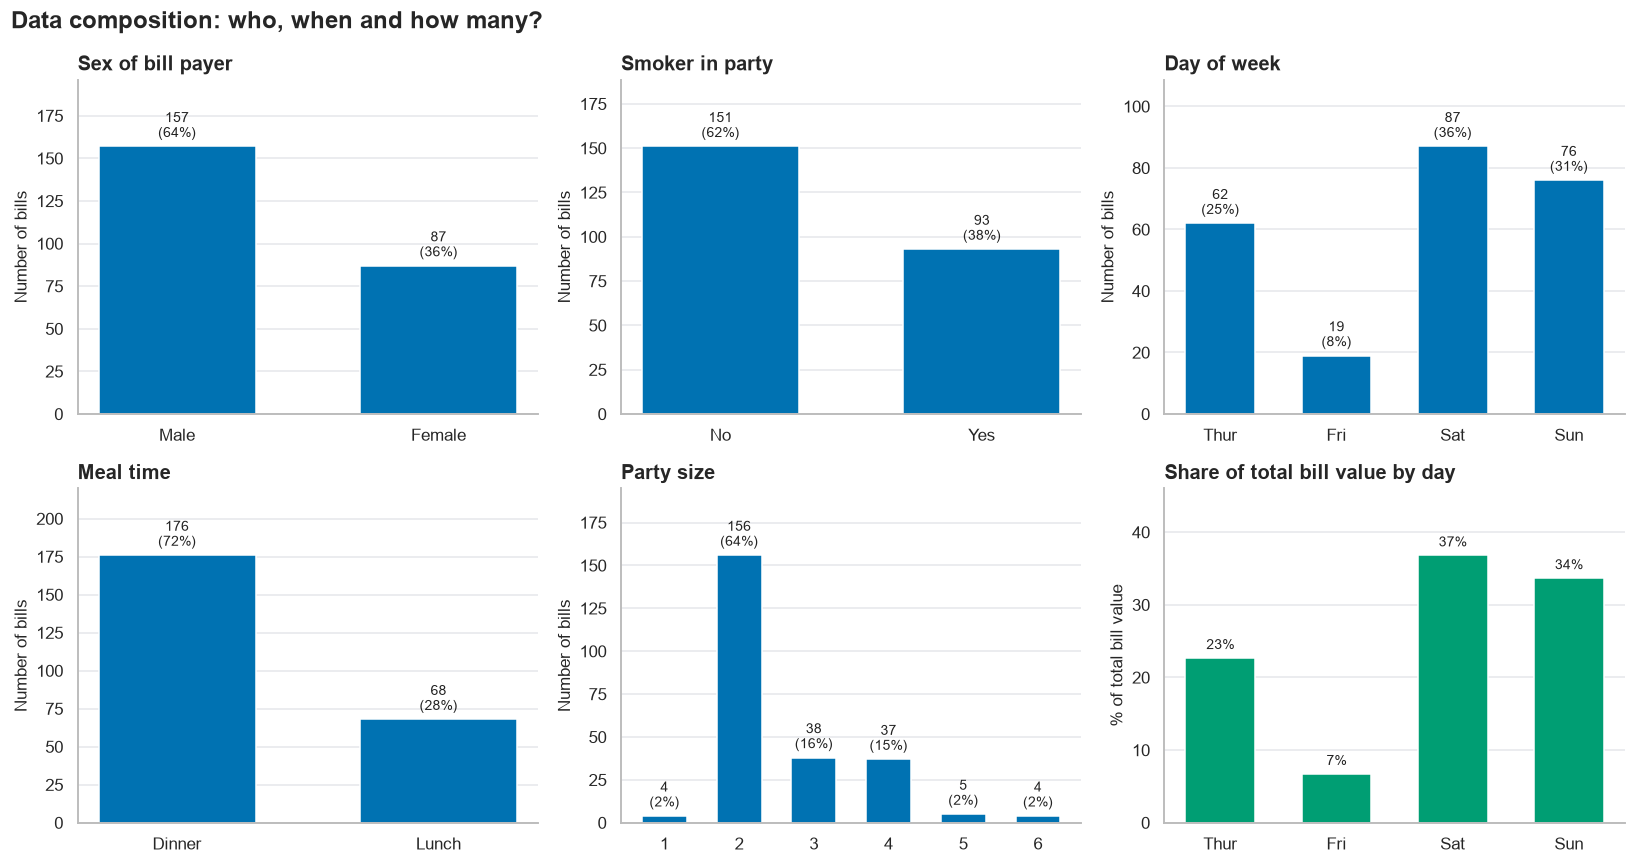

In [41]:
# --- Composition plot: how is the dataset made up? ---
orders = {
    "sex": df["sex"].value_counts().index.tolist(),
    "smoker": df["smoker"].value_counts().index.tolist(),
    "day": DAY_ORDER,
    "time": df["time"].value_counts().index.tolist(),
    "size": sorted(df["size"].unique()),
}
titles = {"sex": "Sex of bill payer", "smoker": "Smoker in party", "day": "Day of week",
          "time": "Meal time", "size": "Party size"}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), list(orders)):
    counts = df[c].value_counts().reindex(orders[c])
    bars = ax.bar(counts.index.astype(str), counts.values, color=BLUE, width=0.6)
    for b, v in zip(bars, counts.values):
        ax.text(b.get_x() + b.get_width() / 2, v + counts.max() * 0.02,
                f"{v}\n({v / len(df):.0%})", ha="center", va="bottom", fontsize=9, color=INK)
    ax.set_title(titles[c])
    ax.set_ylabel("Number of bills")
    ax.set_xlabel("")
    ax.set_ylim(0, counts.max() * 1.25)
    ax.grid(axis="x", visible=False)

# Sixth panel: revenue composition (share of total bill value by day)
ax = axes[1, 2]
rev = df.groupby("day", observed=True)["total_bill"].sum().reindex(DAY_ORDER)
share = rev / rev.sum() * 100
bars = ax.bar(share.index.astype(str), share.values, color=GREEN, width=0.6)
for b, v in zip(bars, share.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.8, f"{v:.0f}%", ha="center", va="bottom", fontsize=9, color=INK)
ax.set_title("Share of total bill value by day")
ax.set_ylabel("% of total bill value")
ax.set_ylim(0, share.max() * 1.25)
ax.grid(axis="x", visible=False)

fig.suptitle("Data composition: who, when and how many?", fontsize=16, fontweight="bold", x=0.01, ha="left")
plt.tight_layout()
save_fig("01_composition")
plt.show()

**Interpretation (Figure 1)**

- **Customers:** bills are paid mostly by **men (64 %)** and **non-smoking parties (62 %)**.
- **Timing:** **dinner accounts for 72 %** of bills and **Saturday + Sunday for 67 %**. Friday is thin (only 19 bills, 8 %), so any Friday conclusion is statistically fragile.
- **Party size:** **two-person tables make up 64 %** of the data; parties of 1, 5 or 6 total just 13 bills, so estimates for those sizes are unreliable.
- **Revenue:** the share of total bill value mirrors the traffic: Saturday (37 %) and Sunday (34 %) generate over 70 % of revenue, Thursday 23 %, Friday only 7 %.
- **Business takeaway:** the data describe a weekend-dinner, couples-dominated restaurant. Findings should not be generalised to weekday lunches or large groups without caution.

---
## Data distribution

Here we study the *shape* of the continuous variables: centre, spread, skewness, outliers and closeness to a normal distribution. This matters because it decides which statistical tests are valid later on.

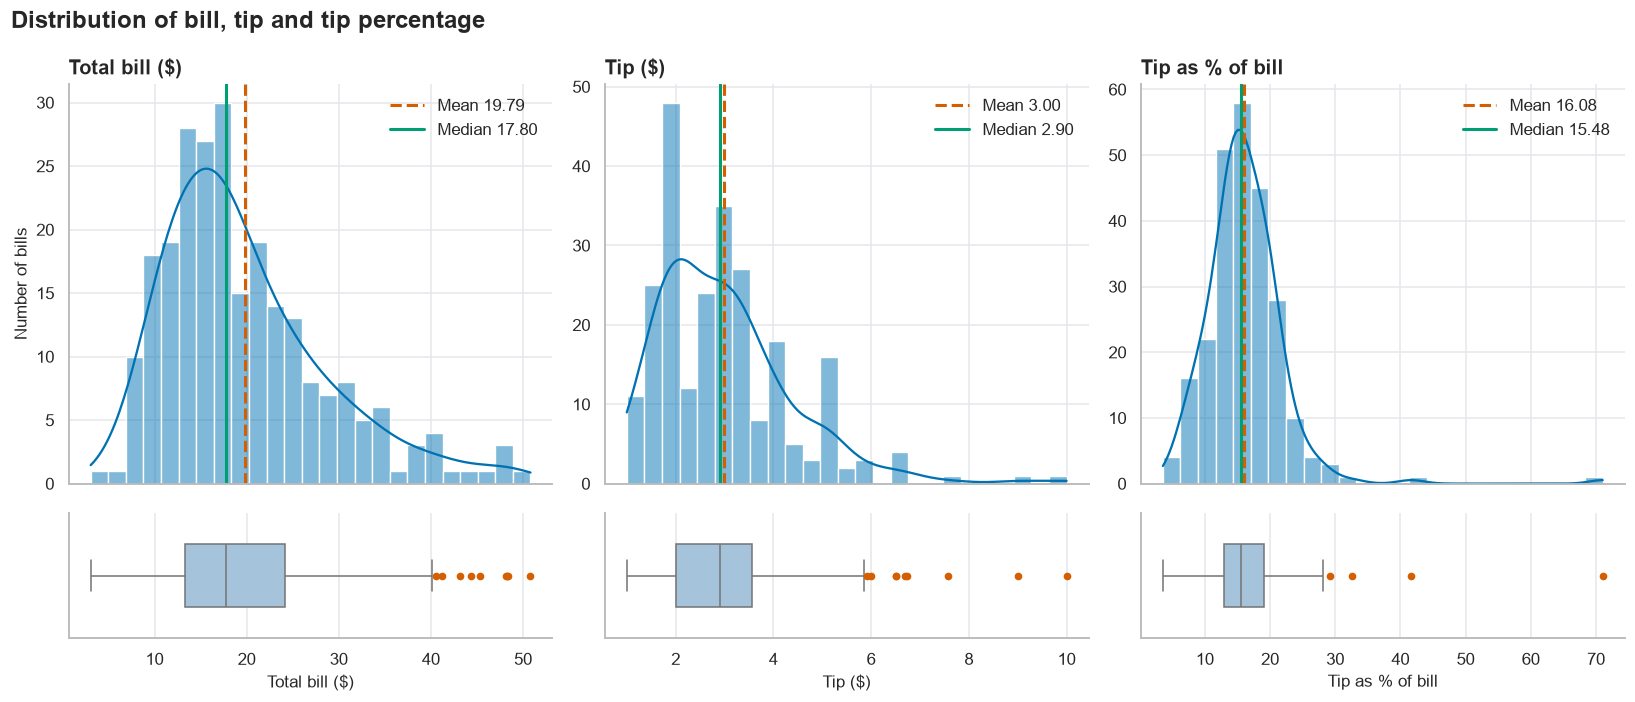

In [42]:
# --- Distribution of the three continuous measures ---
dist_vars = {"total_bill": "Total bill ($)", "tip": "Tip ($)", "tip_pct": "Tip as % of bill"}

fig, axes = plt.subplots(2, 3, figsize=(15, 6.5), sharex="col",
                         gridspec_kw={"height_ratios": [3.2, 1]})
for i, (c, label) in enumerate(dist_vars.items()):
    ax_h, ax_b = axes[0, i], axes[1, i]
    sns.histplot(df[c], bins=25, kde=True, color=BLUE, edgecolor="white", ax=ax_h)
    ax_h.axvline(df[c].mean(), color=VERMILLION, ls="--", lw=2, label=f"Mean {df[c].mean():.2f}")
    ax_h.axvline(df[c].median(), color=GREEN, ls="-", lw=2, label=f"Median {df[c].median():.2f}")
    ax_h.set_title(label)
    ax_h.set_xlabel("")
    ax_h.set_ylabel("Number of bills" if i == 0 else "")
    ax_h.legend(frameon=False)
    sns.boxplot(x=df[c], ax=ax_b, color="#9CC4E4", width=0.5, fliersize=4,
                flierprops={"markerfacecolor": VERMILLION, "markeredgecolor": VERMILLION})
    ax_b.set_xlabel(label)
    ax_b.set_yticks([])
    ax_b.grid(axis="y", visible=False)

fig.suptitle("Distribution of bill, tip and tip percentage", fontsize=16, fontweight="bold", x=0.01, ha="left")
plt.tight_layout()
save_fig("02_distributions")
plt.show()

**Interpretation (Figure 2)**

- **Total bill:** unimodal with a long right tail. Most bills are between \$13 and \$24 (IQR), the median is \$17.80, and the mean (\$19.79) is dragged right by a few bills above \$40.
- **Tip:** peaks around \$2-\$3 with a right tail up to \$10. Tips cluster on round amounts (\$2, \$3), which is visible as small spikes in the histogram, typical of human-chosen values.
- **Tip %:** tightly concentrated around **15 %** (IQR 12.9 %-19.1 %), consistent with the conventional tipping norm, with one very extreme point at 71 %.
- The box plots confirm the red outlier dots sit only on the **high side** for bill and tip.

In [43]:
# --- Shape & normality tests (Shapiro-Wilk: H0 = data are normally distributed) ---
rows = []
for c in ["total_bill", "tip", "tip_pct"]:
    x = df[c]
    w, p = stats.shapiro(x)
    w_log, p_log = stats.shapiro(np.log(x))
    rows.append({
        "variable": c, "skewness": x.skew(), "excess_kurtosis": x.kurt(),
        "shapiro_W": w, "shapiro_p": p, "normal (alpha=0.05)": p > 0.05,
        "skew_after_log": np.log(x).skew(), "shapiro_p_after_log": p_log,
    })
normality = pd.DataFrame(rows).set_index("variable")
display(normality.round(4))

# --- Outliers by the 1.5 x IQR rule ---
out_rows = []
for c in ["total_bill", "tip", "tip_pct"]:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[c] < lo) | (df[c] > hi)).sum()
    out_rows.append({"variable": c, "Q1": q1, "Q3": q3, "lower_fence": lo, "upper_fence": hi,
                     "n_outliers": n_out, "outlier_%": n_out / len(df) * 100})
display(pd.DataFrame(out_rows).set_index("variable").round(2))

,skewness,excess_kurtosis,shapiro_W,shapiro_p,normal (alpha=0.05),skew_after_log,shapiro_p_after_log
variable,,,,,,,
total_bill,1.1332,1.2185,0.9197,0.0,False,-0.1162,0.1576
tip,1.4655,3.6484,0.8978,0.0,False,0.0763,0.0562
tip_pct,3.3492,27.1315,0.7994,0.0,False,-0.3662,0.0000


,Q1,Q3,lower_fence,upper_fence,n_outliers,outlier_%
variable,,,,,,
total_bill,13.35,24.13,-2.82,40.30,9,3.69
tip,2.00,3.56,-0.34,5.91,9,3.69
tip_pct,12.91,19.15,3.56,28.50,4,1.64


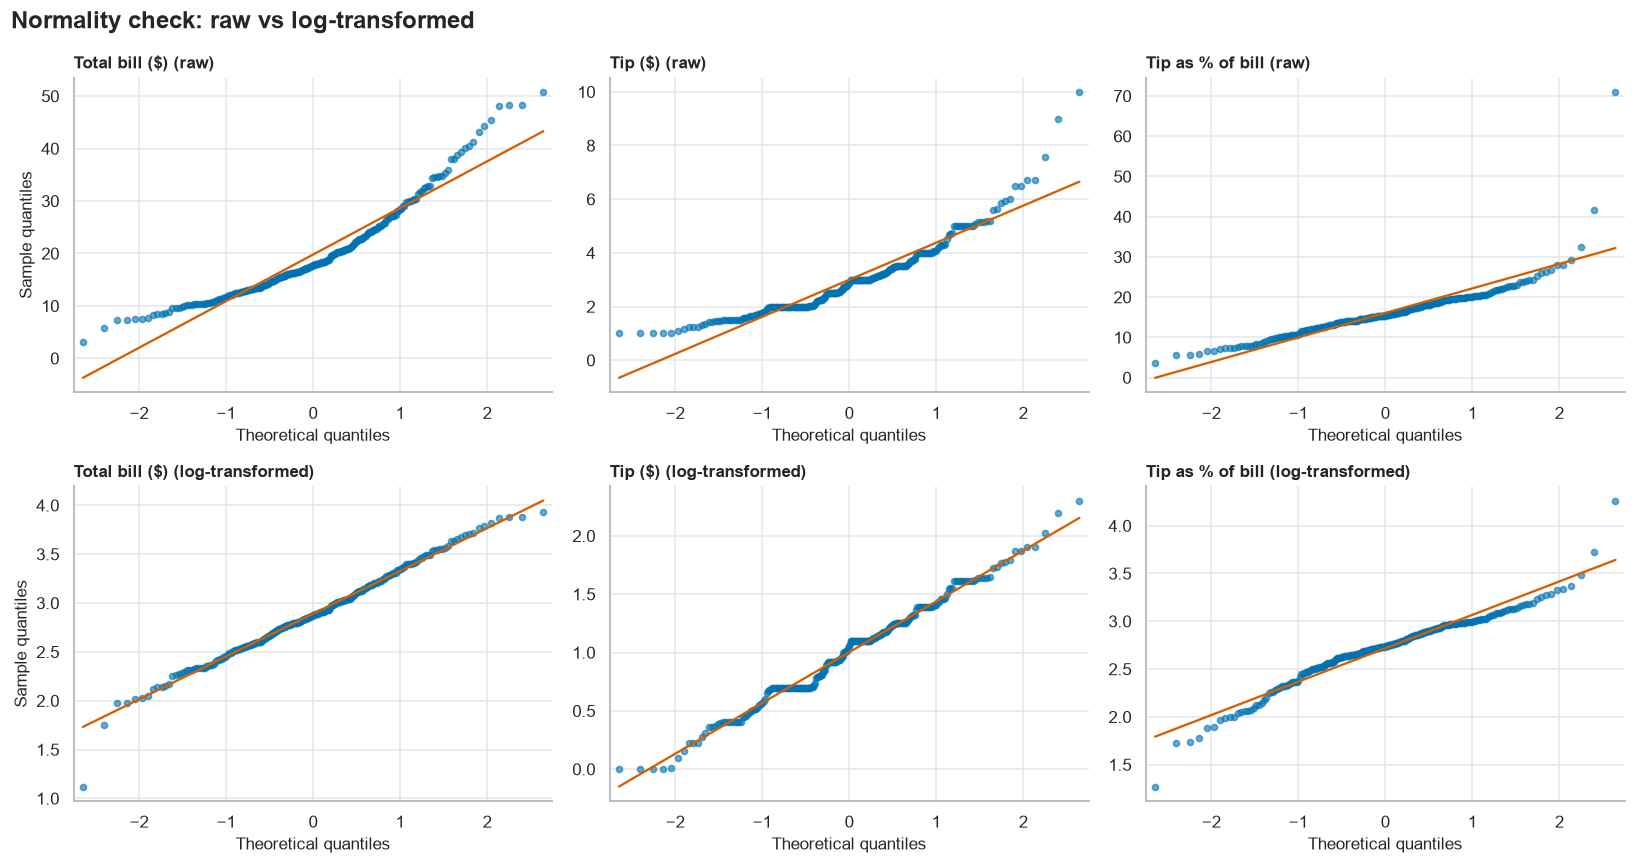

In [44]:
# --- Q-Q plots: points on the red line = normal distribution ---
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, (c, label) in enumerate(dist_vars.items()):
    for r, (data, tag) in enumerate([(df[c], "raw"), (np.log(df[c]), "log-transformed")]):
        sm.qqplot(data, line="s", ax=axes[r, i], markerfacecolor=BLUE, markeredgecolor=BLUE,
                  alpha=0.6, markersize=4)
        axes[r, i].get_lines()[1].set_color(VERMILLION)
        axes[r, i].set_title(f"{label} ({tag})", fontsize=11)
        axes[r, i].set_xlabel("Theoretical quantiles")
        axes[r, i].set_ylabel("Sample quantiles" if i == 0 else "")
fig.suptitle("Normality check: raw vs log-transformed", fontsize=16, fontweight="bold", x=0.01, ha="left")
plt.tight_layout()
save_fig("03_qqplots")
plt.show()

**Interpretation (Table above and Figure 3)**

- **Skewness:** total bill 1.13, tip 1.47 and tip % 3.35, all clearly positive (right-skewed).
- **Shapiro-Wilk test** (H0: the data are normal): p < 0.001 for all three variables, so **normality is rejected** for the raw data. The Q-Q plots agree: the upper tail bends away from the red line.
- **Log transformation:** after taking logs the skewness drops to about -0.12 (bill) and +0.08 (tip), the Q-Q points follow the line closely and Shapiro-Wilk no longer rejects normality at the 5 % level (p = 0.16 and 0.06). **Bill and tip amounts are therefore approximately log-normal.**
- Tip % remains non-normal even after the log transform (p < 0.001) because of the 71 % outlier and a heavy lower tail.
- **Outliers (1.5 x IQR rule):** 9 bills above \$40.30 (3.7 %), 9 tips above \$5.91 (3.7 %) and 4 tip percentages outside 3.6 %-28.5 % (1.6 %). They are plausible large-party bills, not errors (except possibly the 71 % tip), so they are **retained**.
- **Implication:** the later analysis reports medians next to means and confirms every parametric test (t-test, ANOVA) with a non-parametric counterpart (Mann-Whitney, Kruskal-Wallis).

---
## Data comparison

Do different groups (sex, smoking status, day, meal time) pay different bills or tip differently? Tip percentage is the main comparison metric, because raw tip dollars simply follow bill size.

In [45]:
# --- Group summaries ---
for c in CAT_COLS:
    g = (df.groupby(c, observed=True)
           .agg(n=("tip", "size"), mean_bill=("total_bill", "mean"), mean_tip=("tip", "mean"),
                mean_tip_pct=("tip_pct", "mean"), median_tip_pct=("tip_pct", "median"),
                std_tip_pct=("tip_pct", "std"))
           .round(2))
    print(f"\nBy {c.upper()}")
    display(g)


By SEX


,n,mean_bill,mean_tip,mean_tip_pct,median_tip_pct,std_tip_pct
sex,,,,,,
Male,157,20.74,3.09,15.77,15.35,6.48
Female,87,18.06,2.83,16.65,15.56,5.36



By SMOKER


,n,mean_bill,mean_tip,mean_tip_pct,median_tip_pct,std_tip_pct
smoker,,,,,,
Yes,93,20.76,3.01,16.32,15.38,8.51
No,151,19.19,2.99,15.93,15.56,3.99



By DAY


,n,mean_bill,mean_tip,mean_tip_pct,median_tip_pct,std_tip_pct
day,,,,,,
Thur,62,17.68,2.77,16.13,15.38,3.87
Fri,19,17.15,2.73,16.99,15.56,4.77
Sat,87,20.44,2.99,15.32,15.18,5.13
Sun,76,21.41,3.26,16.69,16.11,8.47



By TIME


,n,mean_bill,mean_tip,mean_tip_pct,median_tip_pct,std_tip_pct
time,,,,,,
Lunch,68,17.17,2.73,16.41,15.41,4.02
Dinner,176,20.80,3.10,15.95,15.54,6.75


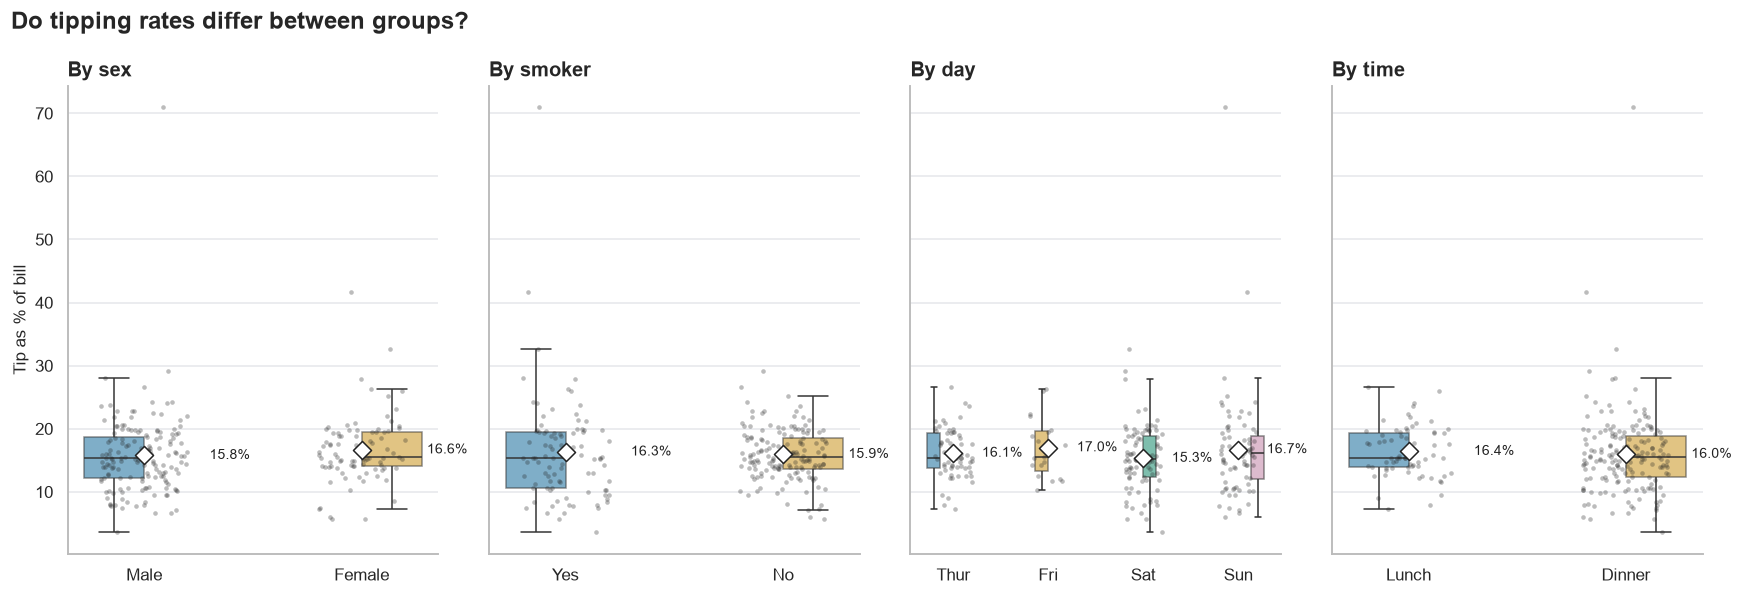

In [46]:
# --- Tip percentage across groups (box = middle 50%, dots = bills, diamond = mean) ---
fig, axes = plt.subplots(1, 4, figsize=(16, 5.5), sharey=True)
for ax, c in zip(axes, CAT_COLS):
    order = list(df[c].cat.categories)
    colors = CAT[:len(order)]
    sns.boxplot(data=df, x=c, y="tip_pct", order=order, hue=c, hue_order=order, palette=colors,
                legend=False, showfliers=False, width=0.55, boxprops={"alpha": 0.55}, ax=ax)
    sns.stripplot(data=df, x=c, y="tip_pct", order=order, color=INK, alpha=0.3, size=3, jitter=0.2, ax=ax)
    means = df.groupby(c, observed=True)["tip_pct"].mean().reindex(order)
    ax.scatter(range(len(order)), means.values, marker="D", s=70, color="white", edgecolor=INK, zorder=5)
    for k, m in enumerate(means.values):
        ax.text(k + 0.3, m, f"{m:.1f}%", va="center", fontsize=9, color=INK)
    ax.set_title(f"By {c}")
    ax.set_xlabel("")
    ax.set_ylabel("Tip as % of bill" if c == CAT_COLS[0] else "")
    ax.grid(axis="x", visible=False)
fig.suptitle("Do tipping rates differ between groups?", fontsize=16, fontweight="bold", x=0.01, ha="left")
plt.tight_layout()
save_fig("04_tip_pct_by_group")
plt.show()

**Interpretation (Figure 4)**

- Across all four groupings the **boxes overlap almost completely** and the group means (diamonds) lie in a narrow band of **15.3 %-17.0 %**. Tipping behaviour is remarkably uniform.
- **Smokers** show a visibly wider box and whiskers (SD 8.5 pts vs 4.0 pts for non-smokers). Part of this is the single 71 % outlier, but smokers also include more low tippers, so they are *less predictable*, not more or less generous on average.
- **Saturday** has the lowest mean tip rate (15.3 %) and **Friday** the highest (17.0 %), but Friday has only 19 bills, so its box is based on little data.

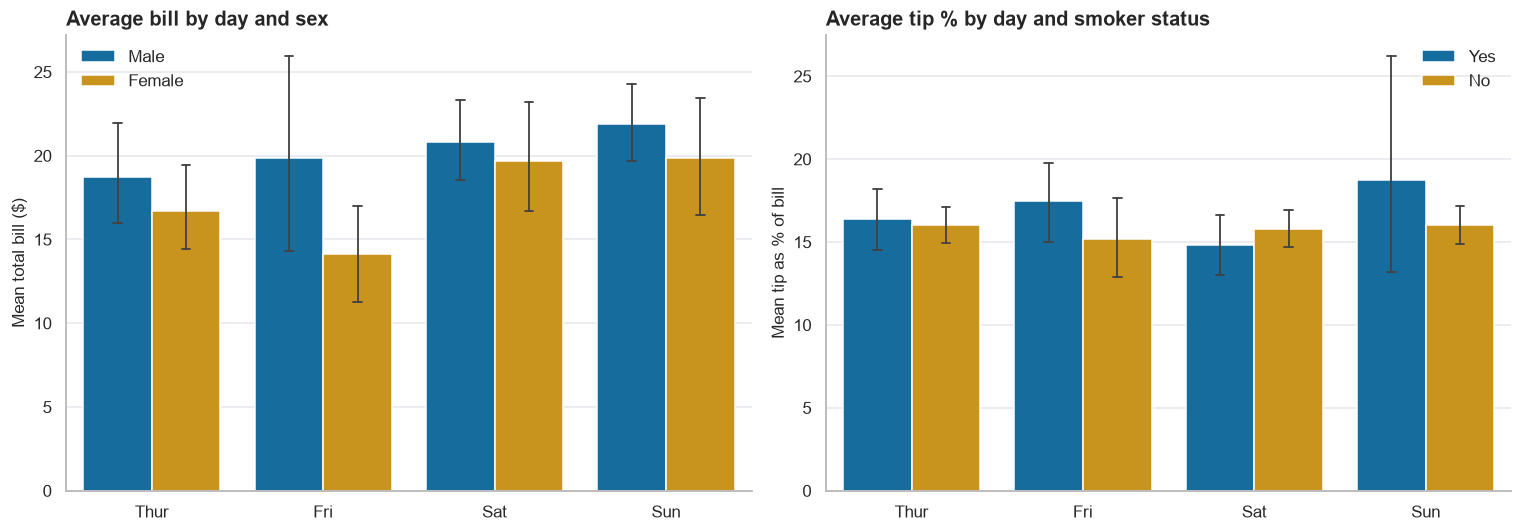

In [47]:
# --- Bill size and tip rate by day, split by sex and smoker (mean with 95% CI) ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=df, x="day", y="total_bill", hue="sex", order=DAY_ORDER, palette=[BLUE, ORANGE],
            errorbar=("ci", 95), capsize=0.1, err_kws={"linewidth": 1.2}, ax=axes[0])
axes[0].set_title("Average bill by day and sex")
axes[0].set_ylabel("Mean total bill ($)")
sns.barplot(data=df, x="day", y="tip_pct", hue="smoker", order=DAY_ORDER, palette=[BLUE, ORANGE],
            errorbar=("ci", 95), capsize=0.1, err_kws={"linewidth": 1.2}, ax=axes[1])
axes[1].set_title("Average tip % by day and smoker status")
axes[1].set_ylabel("Mean tip as % of bill")
for ax in axes:
    ax.set_xlabel("")
    ax.grid(axis="x", visible=False)
    ax.legend(frameon=False, title=None)
plt.tight_layout()
save_fig("05_group_means")
plt.show()

**Interpretation (Figure 5, bars show mean with 95 % confidence interval)**

- **Bill size:** men's average bill is higher than women's on **all four days** (the gap is largest on Friday) and Sunday has the largest bills; most intervals overlap, so single-day gaps are not conclusive. Friday intervals are wide because of the small sample.
- **Tip rate:** the confidence intervals of smokers and non-smokers overlap on every day, so there is **no reliable difference in tip percentage by smoking status on any day**.

In [48]:
# --- Two-group comparisons: Welch t-test, Mann-Whitney U and Cohen's d ---
def compare_two(metric, group):
    levels = list(df[group].cat.categories)
    a = df.loc[df[group] == levels[0], metric]
    b = df.loc[df[group] == levels[1], metric]
    t_stat, t_p = stats.ttest_ind(a, b, equal_var=False)
    u_stat, u_p = stats.mannwhitneyu(a, b, alternative="two-sided")
    pooled_sd = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    return {"metric": metric, "group": group, "levels": f"{levels[0]} vs {levels[1]}",
            "mean_diff": a.mean() - b.mean(), "t_stat": t_stat, "welch_p": t_p,
            "mannwhitney_p": u_p, "cohens_d": (a.mean() - b.mean()) / pooled_sd,
            "significant (p<0.05)": (t_p < 0.05) and (u_p < 0.05)}

two_group = pd.DataFrame([compare_two(m, g) for m in ["tip_pct", "tip", "total_bill"]
                          for g in ["sex", "smoker", "time"]])
display(two_group.round(4))

# --- Four-group comparison across days: one-way ANOVA, Kruskal-Wallis, Tukey post-hoc ---
for metric in ["tip_pct", "total_bill"]:
    groups = [df.loc[df["day"] == d, metric] for d in DAY_ORDER]
    f_stat, f_p = stats.f_oneway(*groups)
    h_stat, h_p = stats.kruskal(*groups)
    print(f"\n{metric} across days -> ANOVA F={f_stat:.2f}, p={f_p:.4f} | Kruskal-Wallis H={h_stat:.2f}, p={h_p:.4f}")
    tukey = pairwise_tukeyhsd(df[metric], df["day"].astype(str), alpha=0.05)
    print(tukey.summary())

,metric,group,levels,mean_diff,t_stat,welch_p,mannwhitney_p,cohens_d,significant (p<0.05)
0,tip_pct,sex,Male vs Female,-0.8840,-1.1433,0.2542,0.1352,-0.1448,False
1,tip_pct,smoker,Yes vs No,0.3868,0.4112,0.6817,0.5607,0.0632,False
2,tip_pct,time,Lunch vs Dinner,0.4610,0.6540,0.5138,0.2303,0.0754,False
3,tip,sex,Male vs Female,0.2562,1.4895,0.1378,0.3834,0.1855,False
4,tip,smoker,Yes vs No,0.0169,0.0918,0.9269,0.7919,0.0122,False
5,tip,time,Lunch vs Dinner,-0.3746,-2.0593,0.0413,0.0288,-0.2722,True
6,total_bill,sex,Male vs Female,2.6872,2.3734,0.0186,0.0214,0.3044,True
7,total_bill,smoker,Yes vs No,1.5681,1.2843,0.2008,0.3413,0.1764,False
8,total_bill,time,Lunch vs Dinner,-3.6285,-3.1230,0.0022,0.0012,-0.4137,True



tip_pct across days -> ANOVA F=0.85, p=0.4688 | Kruskal-Wallis H=1.84, p=0.6069
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
   Fri    Sat  -1.6761 0.7004  -5.681 2.3287  False
   Fri    Sun  -0.3016 0.9975  -4.358 3.7549  False
   Fri   Thur  -0.8637 0.9494 -5.0108 3.2833  False
   Sat    Sun   1.3746 0.4806 -1.1086 3.8577  False
   Sat   Thur   0.8124 0.8545 -1.8161 3.4409  False
   Sun   Thur  -0.5622 0.9498 -3.2686 2.1443  False
---------------------------------------------------

total_bill across days -> ANOVA F=2.77, p=0.0425 | Kruskal-Wallis H=10.40, p=0.0154
Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
   Fri    Sat   3.2898 0.4541 -2.4799  9.0595  False
   Fri    Sun   4.2584 0.2371 -1.5856 10.1025  False
   Fri   Thur   0.5312 0.9957 -5.4434  6.5057  Fa

**Interpretation of the statistical tests** (significance level 5 %; a result is flagged only if both the Welch t-test and the Mann-Whitney U test agree)

| Question | Result | Conclusion |
|---|---|---|
| Tip % by sex | 15.8 % vs 16.6 %, p = 0.25 | No difference |
| Tip % by smoker | 16.3 % vs 15.9 %, p = 0.68 | No difference |
| Tip % by meal time | 16.4 % vs 16.0 %, p = 0.51 | No difference |
| Tip % by day (ANOVA / Kruskal) | p = 0.47 / 0.61 | No difference between days |
| Bill by meal time | Dinner bills are **\$3.63 higher**, p = 0.002, Cohen's d = 0.41 | **Significant**, small-to-medium effect |
| Bill by sex | Men's bills are **\$2.69 higher**, p = 0.019, d = 0.30 | **Significant**, small effect |
| Tip \$ by meal time | Dinner tips are **\$0.37 higher**, p = 0.041, d = 0.27 | Borderline, small effect |
| Bill by day | ANOVA p = 0.043, Kruskal p = 0.015, but **no Tukey pair is significant** (Sun vs Thu p = 0.067) | Weak evidence only |

- **Main finding:** people tip about **16 % regardless of who they are or when they eat**. Groups differ in how much they *spend*, not in how generously they tip.
- Men's higher absolute tip (\$3.09 vs \$2.83) is **not significant** (p = 0.14); it is explained by their larger bills.
- **Caution:** nine two-group tests were run, so borderline results (p close to 0.04) could appear by chance. The meal-time bill difference (p = 0.002) is the only one that is robust to a Bonferroni correction (threshold 0.0056).

---
## Data relationship

How do the variables move together? We examine numerical pairs (correlation, regression), then categorical pairs (chi-square).

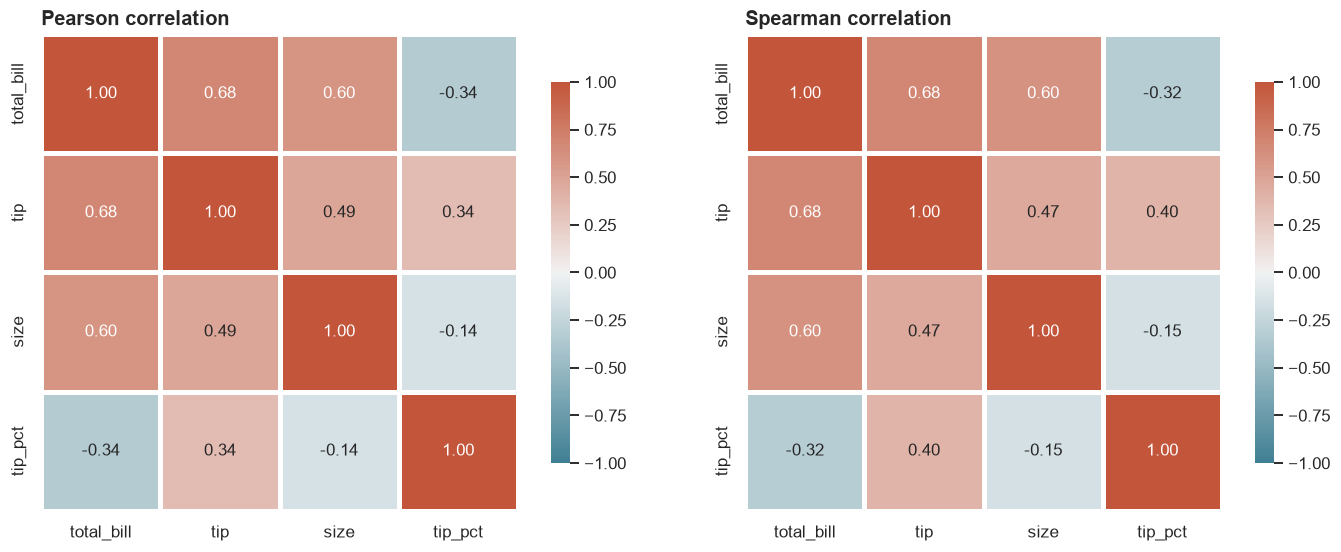

,x,y,pearson_r,ci95_low,ci95_high,pearson_p,spearman_rho,spearman_p
0,total_bill,tip,0.6757,0.6012,0.7386,0.0000,0.6790,0.0000
1,size,tip,0.4893,0.3875,0.5793,0.0000,0.4683,0.0000
2,total_bill,size,0.5983,0.5111,0.6733,0.0000,0.6048,0.0000
3,total_bill,tip_pct,-0.3386,-0.4453,-0.2225,0.0000,-0.3207,0.0000
4,size,tip_pct,-0.1429,-0.2637,-0.0176,0.0256,-0.1522,0.0173


In [49]:
# --- Correlation matrices ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, method in zip(axes, ["pearson", "spearman"]):
    corr = df[NUM_COLS].corr(method=method)
    sns.heatmap(corr, annot=True, fmt=".2f", cmap=DIVERGING, vmin=-1, vmax=1, center=0,
                square=True, linewidths=2, linecolor="white", cbar_kws={"shrink": 0.8},
                annot_kws={"fontsize": 11}, ax=ax)
    ax.set_title(f"{method.capitalize()} correlation")
plt.tight_layout()
save_fig("06_correlation")
plt.show()

# --- Significance of the key relationships ---
pairs = [("total_bill", "tip"), ("size", "tip"), ("total_bill", "size"),
         ("total_bill", "tip_pct"), ("size", "tip_pct")]
rows = []
for x, y in pairs:
    res_p = stats.pearsonr(df[x], df[y])
    ci = res_p.confidence_interval()
    rho, p_s = stats.spearmanr(df[x], df[y])
    rows.append({"x": x, "y": y, "pearson_r": res_p.statistic, "ci95_low": ci.low, "ci95_high": ci.high,
                 "pearson_p": res_p.pvalue, "spearman_rho": rho, "spearman_p": p_s})
display(pd.DataFrame(rows).round(4))

**Interpretation (Figure 6 and table)**

- **Total bill vs tip: r = 0.68** (95 % CI 0.60-0.74, p < 0.001). This is the strongest relationship in the data; Spearman's rho (0.68) is identical, so the link is not driven by outliers.
- **Party size vs tip: r = 0.49** and **bill vs party size: r = 0.60**. Larger parties order more, and so tip more in dollars.
- **Bill vs tip %: r = -0.34** (p < 0.001): the bigger the bill, the *lower* the percentage tipped. **Party size vs tip %** is only weakly negative (r = -0.14, p = 0.026), a small effect.
- Pearson and Spearman matrices tell the same story, so the conclusions are robust to the skewed distributions.
- Correlation does not prove causation: bill and party size are themselves correlated, which is untangled in the regression below.

RuntimeError: `lowess=True` requires statsmodels, an optional dependency, to be installed.

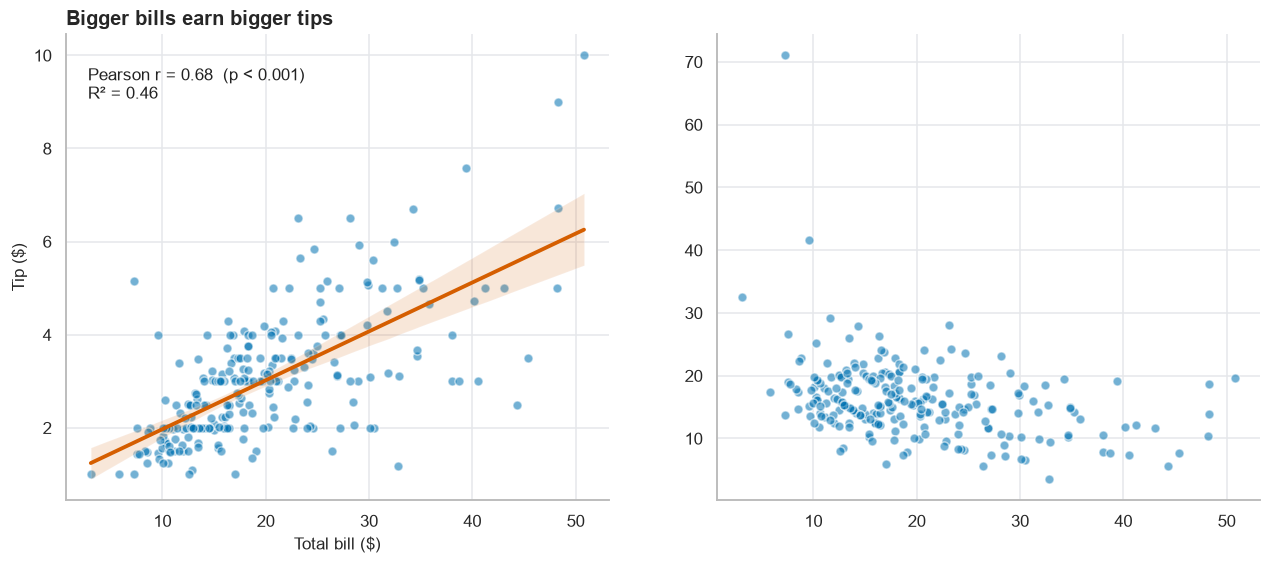

In [50]:
# --- Bill vs tip: the core relationship ---
r, p = stats.pearsonr(df["total_bill"], df["tip"])
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.regplot(data=df, x="total_bill", y="tip", ax=axes[0],
            scatter_kws={"alpha": 0.55, "s": 35, "color": BLUE, "edgecolor": "white"},
            line_kws={"color": VERMILLION, "lw": 2.5})
axes[0].set_title("Bigger bills earn bigger tips")
axes[0].set_xlabel("Total bill ($)")
axes[0].set_ylabel("Tip ($)")
axes[0].text(0.04, 0.93, f"Pearson r = {r:.2f}  (p < 0.001)\nR\u00b2 = {r**2:.2f}",
             transform=axes[0].transAxes, va="top", fontsize=11, color=INK)

sns.regplot(data=df, x="total_bill", y="tip_pct", lowess=True, ax=axes[1],
            scatter_kws={"alpha": 0.55, "s": 35, "color": BLUE, "edgecolor": "white"},
            line_kws={"color": VERMILLION, "lw": 2.5})
axes[1].set_title("...but the tip rate falls as bills grow")
axes[1].set_xlabel("Total bill ($)")
axes[1].set_ylabel("Tip as % of bill")
axes[1].text(0.97, 0.93, "Red line: LOWESS trend", transform=axes[1].transAxes,
             ha="right", va="top", fontsize=10, color=MUTED)
plt.tight_layout()
save_fig("07_bill_vs_tip")
plt.show()

**Interpretation (Figure 7)**

- **Left:** a clear positive linear trend. The bill alone explains **R\u00b2 = 0.46 (46 %)** of the variation in tips. The scatter fans out at larger bills, i.e. big bills are tipped less predictably.
- **Right:** the LOWESS curve shows tip % **declining steadily from roughly 19 % on the smallest bills to about 11-12 % on bills above \$30, flattening at the high end**. Small bills are tipped at a higher rate, consistent with people rounding up or leaving a minimum tip. The 71 % point (a \$7 bill) is clearly visible as the outlier.
- Together: **tips grow with the bill, but less than proportionally** at the low end, so the dollar tip is not a constant percentage.

In [ ]:
# --- Does the bill-tip slope change by meal time or smoker status? ---
g = sns.lmplot(data=df, x="total_bill", y="tip", hue="smoker", hue_order=["No", "Yes"], col="time",
               col_order=["Lunch", "Dinner"], palette=[BLUE, ORANGE], height=5, aspect=1.15,
               scatter_kws={"alpha": 0.6, "s": 35, "edgecolor": "white"}, line_kws={"lw": 2.5})
g.set_axis_labels("Total bill ($)", "Tip ($)")
g.set_titles("{col_name}")
g.legend.set_title("Smoker")
g.figure.suptitle("Bill-tip relationship by meal time and smoker status", fontsize=15,
                  fontweight="bold", x=0.01, ha="left", y=1.03)
save_fig("08_bill_tip_facets")
plt.show()

**Interpretation (Figure 8)**

- Dinner, non-smokers: the steepest slope, tipping rises tightly with the bill.
- Dinner, smokers: a flatter slope and much wider confidence band, so the tip is **less related to the bill size**; some smokers leave large tips on small bills and vice versa.
- Lunch: the two lines are close and their bands overlap heavily, partly because there are only 68 lunch bills.
- Take care: these are visual trends from small subgroups, they should be formally tested (interaction term) before being treated as fact.

In [ ]:
# --- Party size: absolute tip vs tip rate ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sizes = sorted(df["size"].unique())

sns.boxplot(data=df, x="size", y="tip", order=sizes, color="#9CC4E4", width=0.55, showfliers=False, ax=axes[0])
sns.stripplot(data=df, x="size", y="tip", order=sizes, color=INK, alpha=0.3, size=3, jitter=0.2, ax=axes[0])
axes[0].set_title("Tip amount rises with party size")
axes[0].set_ylabel("Tip ($)")

sns.pointplot(data=df, x="size", y="tip_pct", order=sizes, errorbar=("ci", 95), color=BLUE,
              markers="o", linestyles="-", ax=axes[1])
axes[1].set_title("...but tip rate does not rise (mean, 95% CI)")
axes[1].set_ylabel("Tip as % of bill")
for ax in axes:
    ax.set_xlabel("Party size")
    ax.grid(axis="x", visible=False)
plt.tight_layout()
save_fig("09_party_size")
plt.show()

# Group counts matter when reading the CIs above
print(df["size"].value_counts().sort_index().to_string())

**Interpretation (Figure 9)**

- **Left:** the median tip rises from about \$1.4 for singles to \$2.5 for pairs, \$3.3 for trios and \$3.8 for groups of four. Larger groups tip more dollars.
- **Right:** the tip *percentage* does **not** rise with party size; it falls from the party of one (which has only 4 bills and an enormous interval) to about 15 %, and then stays flat. Larger parties therefore tip more because they spend more, not because they tip more generously.
- Parties of 1, 5 and 6 have 4-5 bills each, so their intervals are very wide and should not be over-interpreted.

In [ ]:
# --- Categorical vs categorical: Chi-square test of independence ---
def cramers_v(table):
    chi2 = stats.chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1)))

pairs_cat = [("smoker", "day"), ("sex", "smoker"), ("sex", "time"), ("day", "time")]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
res = []
for ax, (a, b) in zip(axes, pairs_cat):
    ct = pd.crosstab(df[a], df[b])
    chi2, p, dof, expected = stats.chi2_contingency(ct)
    res.append({"pair": f"{a} x {b}", "chi2": chi2, "dof": dof, "p_value": p,
                "cramers_V": cramers_v(ct), "min_expected_count": expected.min()})
    sns.heatmap(ct, annot=True, fmt="d", cmap=sns.light_palette(BLUE, as_cmap=True), cbar=False,
                linewidths=2, linecolor="white", ax=ax)
    p_txt = "p < 0.001" if p < 0.001 else f"p = {p:.3f}"
    ax.set_title(f"{a} x {b}\n({p_txt})", fontsize=11)
    ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout()
save_fig("10_categorical_associations")
plt.show()
display(pd.DataFrame(res).set_index("pair").round(4))

**Interpretation (Figure 10 and table)**

- **Smoker x day (p < 0.001, Cramer's V = 0.33, moderate):** the share of smoking parties changes by day, it is highest on Friday (15 of 19) and Saturday (48 %), and lowest on Sunday (25 %) and Thursday (27 %).
- **Sex x time (p = 0.002, V = 0.21, weak-moderate):** female payers are relatively more common at lunch (40 % of women's bills are lunches vs 21 % of men's).
- **Sex x smoker (p = 1.0, V = 0.003):** no association at all; smoking is independent of the payer's sex.
- **Day x time (V = 0.94)** is a *structural* association: lunch is served almost only on Thursday and Friday, dinner on weekends. It is a property of how the data were collected, not a behavioural finding, and means `day` and `time` effects cannot be separated cleanly.

### Multiple regression: what drives the tip?

A linear model `tip ~ total_bill + size` quantifies each driver while holding the other constant.

In [ ]:
# --- Linear regression: what drives the tip? ---
model = smf.ols("tip ~ total_bill + size", data=df).fit()
print(model.summary())

# Model diagnostics
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
axes[0].scatter(model.fittedvalues, model.resid, alpha=0.6, s=30, color=BLUE, edgecolor="white")
axes[0].axhline(0, color=VERMILLION, lw=2)
axes[0].set_title("Residuals vs fitted")
axes[0].set_xlabel("Fitted tip ($)"); axes[0].set_ylabel("Residual ($)")
sm.qqplot(model.resid, line="s", ax=axes[1], markerfacecolor=BLUE, markeredgecolor=BLUE, alpha=0.6, markersize=4)
axes[1].get_lines()[1].set_color(VERMILLION)
axes[1].set_title("Residual Q-Q plot")
sns.histplot(model.resid, bins=25, kde=True, color=BLUE, edgecolor="white", ax=axes[2])
axes[2].set_title("Residual distribution")
axes[2].set_xlabel("Residual ($)")
plt.tight_layout()
save_fig("11_regression_diagnostics")
plt.show()

coefs = pd.concat([model.params, model.conf_int(), model.pvalues], axis=1)
coefs.columns = ["coef", "ci95_low", "ci95_high", "p_value"]
display(coefs.round(4))

**Interpretation (regression output and Figure 11)**

- **Model fit:** R\u00b2 = 0.468 (adjusted 0.463), F-test p < 0.001. Bill and party size together explain about **47 %** of tip variation; the rest is personal choice and service quality, which is not in the data.
- **Total bill:** each extra **\$1 on the bill adds about \$0.093 (9.3 cents) to the tip** (95 % CI \$0.075-\$0.111, p < 0.001), the dominant driver.
- **Party size:** with the bill held constant, each additional diner adds about **\$0.19** (CI \$0.02-\$0.36, p = 0.025), a small but statistically significant effect.
- **Diagnostics:** residuals centre on zero with no curvature, so the linear form is reasonable. However, residuals are **right-skewed** (skew 0.55, Jarque-Bera p < 0.001) and the spread widens at higher predicted tips (mild heteroscedasticity). Coefficients are still useful, but p-values and intervals are somewhat approximate; a log-log model or robust standard errors would be a sensible refinement.
- Because bill and party size are correlated (r = 0.60), the party-size coefficient is the less stable of the two.

---
## Executive summary

| Area | Key finding |
|---|---|
| **Composition** | 244 clean bills, no missing values. Mostly weekend dinners (67 % Sat/Sun, 72 % dinner), male payers (64 %), non-smokers (62 %) and two-person tables (64 %). |
| **Distribution** | Bill and tip are right-skewed and approximately log-normal; tip % is centred near 15-16 % with one extreme 71 % outlier. Use medians and non-parametric checks. |
| **Comparison** | Tip percentage is **statistically the same** for men/women, smokers/non-smokers, all days and both meals. Dinner and male payers have significantly larger bills. |
| **Relationship** | Bill and tip are strongly linked (r = 0.68, R\u00b2 = 0.46). Each extra \$1 of bill adds about 9 cents of tip; tip *rate* falls as bills grow. Party size adds tips in dollars, not in percentage. |
| **Caveats** | Small subgroups (Friday, parties of 1/5/6), observational data, mild heteroscedasticity, and `day` and `time` are almost perfectly confounded. |

**Recommendation:** forecast tips as roughly **15-16 % of the bill** for planning, and focus on drivers of bill size (dinner service, larger parties, weekends) to increase tip income.

*Figures are saved in `../images/` (300 dpi) for inclusion in the written report.*